# During-Inference Ensemble: M1→M4 Sequential (Detector→Reviewer)

Berbeda dari after-inference ensemble yang hanya meng-agregasi output binary,
notebook ini menjalankan **M1 dulu**, lalu **menyuntikkan reasoning M1 ke prompt M4**
sehingga M4 bertindak sebagai reviewer yang informed.

```
CXR Image → M1 (NV-Reason-CXR-3B, Qwen2.5-VL) → reasoning + prediksi
                                                          ↓
CXR Image + M1's reasoning → M4 (MedGemma-4B-IT, Gemma 3) → final decision
```

**M1 data sudah ada** dari Exp1 v2 — hanya M4 yang perlu inference baru.

### Mengapa M4 sebagai Reviewer?
- M4 memiliki respons ICL gradual & proporsional (vs M2 yang resisten)
- Medical-general training → bisa mengevaluasi claims medis tanpa bias CXR-specific
- Cross-architectural diversity: Gemma 3 vs Qwen2.5-VL → error patterns berbeda
- After-inference ensemble M1+M4 sudah menunjukkan S2 > M1 single

## 1 — Setup & Imports

In [1]:
import sys
import json
import time
import re
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np
import torch
from PIL import Image
from tqdm.auto import tqdm

# Add src to path
sys.path.insert(0, str(Path('src').resolve()))
from during_ensemble import (
    SYSTEM_PROMPT_REVIEWER, USER_QUERY_REVIEWER,
    build_reviewer_user_text, build_few_shot_context_v2,
    load_m1_results, get_m1_output,
    load_checkpoint, append_jsonl,
)
from evaluate import extract_diagnosis, compute_classification_metrics

print(f'PyTorch: {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

/data/arta/envs/thoraxai/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.10.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5090
VRAM: 33.7 GB


## 2 — Configuration

In [2]:
# ════════════════════════════════════════════════════════════════════
# KONFIGURASI — SESUAIKAN PATH INI
# ════════════════════════════════════════════════════════════════════

# Model M4 (MedGemma-4B-IT) — path ke model weights
M4_MODEL_PATH = "../models/MedGemma-4B-IT"  # <-- SESUAIKAN

# M1 existing results (dari Exp1 v2)
M1_RESULTS_PATH = Path("result-M1/all_results.jsonl")

# Few-shot example pool CSVs
CHEXPERT_PTX_CSV  = "../data/chexpert_ptx_positive.csv"   # <-- SESUAIKAN
CHEXPERT_NORM_CSV = "../data/chexpert_ptx_negative.csv"   # <-- SESUAIKAN

# Test set image directories
CHEXPERT_TEST_NORMAL_DIR = "../data/chexpert_plus/images/internal_test_normal"  # <-- SESUAIKAN
CHEXPERT_TEST_PTX_DIR    = "../data/chexpert_plus/images/internal_test_pneumothorax"  # <-- SESUAIKAN
CHEXPERT_TEST_CSV        = "../data/chexpert_internal_test.csv"  # <-- SESUAIKAN

RSUNAIR_IMAGES_NORMAL = "../data/rs_unair/images/normal"  # <-- SESUAIKAN
RSUNAIR_IMAGES_PTX    = "../data/rs_unair/images/pneumothorax"  # <-- SESUAIKAN
RSUNAIR_LABELS_CSV    = "../data/rs_unair/labels.csv"  # <-- SESUAIKAN

# Few-shot image pool root (untuk example_selector)
POOL_IMAGES_ROOT = "../data/chexpert_plus/images"  # <-- SESUAIKAN

# Experiment config
K_SHOTS = [0, 1, 4]
SEEDS = [0, 1, 2, 3, 4]
MAX_NEW_TOKENS = 1024
TEMPERATURE = 0.1
TOP_P = 0.9

# Output
OUTPUT_DIR = Path("results-during-ensemble-m1-m4")
OUTPUT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = OUTPUT_DIR / "checkpoint_during_ensemble_m1_m4.jsonl"

print("Config loaded.")
print(f"  M4 model: {M4_MODEL_PATH}")
print(f"  Chexpert PTX CSV: {CHEXPERT_PTX_CSV}")
print(f"  K-shots: {K_SHOTS}")
print(f"  Seeds: {SEEDS}")
print(f"  Output: {OUTPUT_DIR}")

Config loaded.
  M4 model: ../models/MedGemma-4B-IT
  Chexpert PTX CSV: ../data/chexpert_ptx_positive.csv
  K-shots: [0, 1, 4]
  Seeds: [0, 1, 2, 3, 4]
  Output: results-during-ensemble-m1-m4


## 3 — Load M1 Existing Results

In [3]:
df_m1 = load_m1_results(M1_RESULTS_PATH)

# Filter to k_shots we need
df_m1_filtered = df_m1[df_m1['k_shot'].isin(K_SHOTS)].copy()
print(f"\nFiltered to k={K_SHOTS}: {len(df_m1_filtered)} records")
print(df_m1_filtered.groupby(['k_shot', 'test_set']).size().unstack(fill_value=0))

Loaded M1 results: 11950 records
  k_shots: [np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(8)]
  seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']

Filtered to k=[0, 1, 4]: 7170 records
test_set  CheXpert Plus (Internal)  RS UNAIR (External)
k_shot                                                 
0                             1000                 1390
1                             1000                 1390
4                             1000                 1390


## 4 — Load Few-Shot Example Selector

In [4]:
import os

file_path = '../data/rs_unair/images/normal/0124OP47ENZ01.png'

if os.path.exists(file_path):
    print("File ditemukan!")
else:
    print("File TIDAK ditemukan. Coba cek lokasinya lagi.")

File ditemukan!


In [5]:
# We need the same few-shot examples M1 used (same seed → same examples)
try:
    from example_selector import FewShotSelector
    selector = FewShotSelector(
        positive_csv=CHEXPERT_PTX_CSV,
        negative_csv=CHEXPERT_NORM_CSV,
        images_root=POOL_IMAGES_ROOT,
    )
    USE_SELECTOR = True
    print("FewShotSelector loaded successfully.")
except Exception as e:
    USE_SELECTOR = False
    print(f"FewShotSelector not available: {e}")
    print("Few-shot context will be skipped — only M1's output will be given to M4.")
    print("For k=1 and k=4, copy example_selector.py to src/ if you want full context.")

[FewShotSelector] Pool loaded — PTX: 150, Normal: 150
FewShotSelector loaded successfully.


## 5 — Load Test Sets

In [6]:
def load_test_images(csv_path, normal_dir, ptx_dir, name):
    """Load test set image paths and labels."""
    df = pd.read_csv(csv_path)
    rows = []
    
    if 'file_id' in df.columns:
        # CheXpert format
        for _, r in df.iterrows():
            fid = r['file_id']
            label_int = 1 if r['label'] == 'pneumothorax' else 0
            img_dir = ptx_dir if label_int == 1 else normal_dir
            img_path = Path(img_dir) / f"{fid}.jpg"
            if not img_path.exists():
                img_path = Path(img_dir) / f"{fid}.png"
            rows.append({'image_id': fid, 'ground_truth': label_int, 'image_path': str(img_path)})
    elif 'image_id' in df.columns:
        # RS UNAIR format
        for _, r in df.iterrows():
            fname = r['image_id']
            if not fname.endswith(('.png', '.jpg')):
                fname = f"{fname}.png"
            label_int = 1 if r['label'] == 1 else 0
            img_dir = ptx_dir if label_int == 1 else normal_dir
            img_path = Path(img_dir) / fname
            rows.append({'image_id': Path(fname).stem, 'ground_truth': label_int, 'image_path': str(img_path)})
    else:
        raise ValueError(f"Unknown CSV format: {df.columns.tolist()}")
    
    result = pd.DataFrame(rows)
    print(f"  {name}: {len(result)} images (PTX={result['ground_truth'].sum()}, Normal={(result['ground_truth']==0).sum()})")
    return result


print("Loading test sets...")
test_sets = [
    {
        'name': 'CheXpert Plus (Internal)',
        'df': load_test_images(CHEXPERT_TEST_CSV, CHEXPERT_TEST_NORMAL_DIR, CHEXPERT_TEST_PTX_DIR, 'CheXpert'),
    },
    {
        'name': 'RS UNAIR (External)',
        'df': load_test_images(RSUNAIR_LABELS_CSV, RSUNAIR_IMAGES_NORMAL, RSUNAIR_IMAGES_PTX, 'RS UNAIR'),
    },
]
print(f"\nTotal images per inference: {sum(ts['df'].shape[0] for ts in test_sets)}")

Loading test sets...
  CheXpert: 200 images (PTX=100, Normal=100)
  RS UNAIR: 278 images (PTX=173, Normal=105)

Total images per inference: 478


## 6 — Load M4 Model (MedGemma-4B-IT, Gemma 3)

M4 menggunakan arsitektur **Gemma 3**, berbeda dari M2 (Qwen2.5-VL).
Loading menggunakan `Gemma3ForConditionalGeneration` dari transformers.

In [7]:
from transformers import AutoProcessor, BitsAndBytesConfig
from transformers import Gemma3ForConditionalGeneration

print(f"Loading M4 model: {M4_MODEL_PATH}")
print("Architecture: Gemma 3 (MedGemma-4B-IT)")
print("Quantization: 4-bit NF4 (bfloat16 compute)")

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

m4_processor = AutoProcessor.from_pretrained(M4_MODEL_PATH)

m4_model = Gemma3ForConditionalGeneration.from_pretrained(
    M4_MODEL_PATH,
    quantization_config=quant_config,
    device_map="auto",
)
m4_model.eval()

print(f"M4 loaded. Device: {m4_model.device}")
print(f"VRAM used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

The image processor of type `Gemma3ImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Loading M4 model: ../models/MedGemma-4B-IT
Architecture: Gemma 3 (MedGemma-4B-IT)
Quantization: 4-bit NF4 (bfloat16 compute)


Loading weights: 100%|██████████| 883/883 [00:01<00:00, 781.79it/s]


M4 loaded. Device: cuda:0
VRAM used: 3.24 GB


## 7 — M4 Reviewer Inference Function

Menggunakan Gemma 3 chat format (berbeda dari Qwen2.5-VL).

In [8]:
def generate_m4_review(
    image_path: str,
    m1_output: str,
    few_shot_context: str = "",
    max_new_tokens: int = 1024,
    temperature: float = 0.1,
    top_p: float = 0.9,
) -> tuple:
    """
    Run M4 (MedGemma, Gemma 3) as reviewer with M1's output as context.
    
    Returns: (generated_text, inference_time_seconds)
    """
    # Load image
    img = Image.open(image_path)
    if img.mode != 'RGB':
        img = img.convert('RGB')
    
    # Build user text with M1's output
    user_text = build_reviewer_user_text(m1_output, few_shot_context)
    
    # Build messages in Gemma 3 chat format
    content_parts = []
    if user_text:
        content_parts.append({"type": "text", "text": user_text})
    content_parts.append({"type": "image", "image": img})
    content_parts.append({"type": "text", "text": USER_QUERY_REVIEWER})
    
    messages = [
        {
            "role": "system",
            "content": [{"type": "text", "text": SYSTEM_PROMPT_REVIEWER}],
        },
        {
            "role": "user",
            "content": content_parts,
        },
    ]
    
    # Apply chat template
    text = m4_processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    
    # Process inputs
    inputs = m4_processor(
        text=text, images=[img], return_tensors="pt",
    ).to(m4_model.device)
    input_len = inputs["input_ids"].shape[1]
    
    # Generate — greedy decoding (do_sample=False) for reproducibility
    t0 = time.time()
    with torch.no_grad():
        output_ids = m4_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )
    elapsed = time.time() - t0
    
    # Decode only new tokens
    generated_ids = output_ids[:, input_len:]
    result = m4_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    
    # Cleanup
    del inputs, output_ids, generated_ids
    torch.cuda.empty_cache()
    
    return result, elapsed


print("generate_m4_review() defined.")

generate_m4_review() defined.


## 8 — Run During-Ensemble Inference

Untuk setiap (k, seed, test_set, image):
1. Ambil M1's generated_text dari data yang sudah ada
2. Build few-shot context (sama yang M1 terima)
3. Run M4 dengan M1's output + few-shot + image
4. Simpan hasil

In [9]:
import json

# Baca semua record
with open(CHECKPOINT_PATH, 'r') as f:
  all_records = [json.loads(line) for line in f if line.strip()]

# Keep hanya yang berhasil (ada generated_text yang tidak kosong)
good_records = [r for r in all_records if r.get('m4_generated_text', '') != '']

# Tulis ulang checkpoint hanya dengan record yang berhasil
with open(CHECKPOINT_PATH, 'w') as f:
  for r in good_records:
      f.write(json.dumps(r, ensure_ascii=False) + '\n')

print(f"Sebelum: {len(all_records)} records")
print(f"Sesudah: {len(good_records)} records (error dihapus)")

Sebelum: 0 records
Sesudah: 0 records (error dihapus)


In [9]:
# Load checkpoint (untuk resume jika terputus)
done_keys, existing_records = load_checkpoint(CHECKPOINT_PATH)
print(f"Checkpoint: {len(done_keys)} records already done.")

# Count total work
total_inferences = 0
for ts in test_sets:
    for k in K_SHOTS:
        for seed in SEEDS:
            for _, row in ts['df'].iterrows():
                key = (k, seed, ts['name'], row['image_id'])
                if key not in done_keys:
                    total_inferences += 1

print(f"Remaining inferences: {total_inferences}")
print(f"Estimated time: ~{total_inferences * 35 / 3600:.1f} hours (assuming ~35s per inference for M4)")

Checkpoint: 3750 records already done.
Remaining inferences: 3420
Estimated time: ~33.2 hours (assuming ~35s per inference for M4)


In [11]:
  # === DEBUG: Test 1 image ===
  import time, torch
  from PIL import Image

  # Ambil 1 test image
  img_row = test_sets[0]['df'].iloc[0]
  m1_output = get_m1_output(df_m1, 0, 0, test_sets[0]['name'], img_row['image_id'])

  # Build prompt manually
  img = Image.open(img_row['image_path']).convert('RGB')
  user_text = build_reviewer_user_text(m1_output, "")

  content_parts = []
  if user_text:
      content_parts.append({"type": "text", "text": user_text})
  content_parts.append({"type": "image", "image": img})
  content_parts.append({"type": "text", "text": USER_QUERY_REVIEWER})

  messages = [
      {"role": "system", "content": [{"type": "text", "text": SYSTEM_PROMPT_REVIEWER}]},
      {"role": "user", "content": content_parts},
  ]

  text = m4_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
  print("=== PROMPT LENGTH ===")
  print(f"Prompt chars: {len(text)}")
  print(f"Prompt tail: ...{text[-200:]}")

  inputs = m4_processor(text=text, images=[img], return_tensors="pt").to(m4_model.device)
  input_len = inputs["input_ids"].shape[1]
  print(f"\n=== INPUT ===")
  print(f"input_ids shape: {inputs['input_ids'].shape}")
  print(f"input_len: {input_len}")

  t0 = time.time()
  with torch.no_grad():
      output_ids = m4_model.generate(
          **inputs, max_new_tokens=1024, do_sample=False,
      )
  elapsed = time.time() - t0

  print(f"\n=== OUTPUT ===")
  print(f"output_ids shape: {output_ids.shape}")
  print(f"new tokens: {output_ids.shape[1] - input_len}")
  print(f"time: {elapsed:.1f}s")

  # Decode berbagai cara
  generated_ids = output_ids[:, input_len:]
  result_skip = m4_processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
  result_raw = m4_processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
  result_full = m4_processor.batch_decode(output_ids, skip_special_tokens=True)[0]

  print(f"\nDecode (skip_special=True):  len={len(result_skip)}, text='{result_skip[:300]}'")
  print(f"\nDecode (skip_special=False): len={len(result_raw)}, text='{result_raw[:300]}'")
  print(f"\nDecode (full output):        len={len(result_full)}, text='...{result_full[-300:]}'")

=== PROMPT LENGTH ===
Prompt chars: 3206
Prompt tail: ... No Finding </answer><start_of_image>Based on the first reader's analysis above and your own examination of this chest X-ray, provide your second reading assessment.<end_of_turn>
<start_of_turn>model


=== INPUT ===
input_ids shape: torch.Size([1, 990])
input_len: 990

=== OUTPUT ===
output_ids shape: torch.Size([1, 1002])
new tokens: 12
time: 0.7s

Decode (skip_special=True):  len=25, text='NO PNEUMOTHORAX DETECTED
'

Decode (skip_special=False): len=38, text='NO PNEUMOTHORAX DETECTED
<end_of_turn>'

Decode (full output):        len=3171, text='...s are clear, and the cardiomediastinal silhouette is normal. No significant findings are present. </think>
<answer> No Finding </answer>



Based on the first reader's analysis above and your own examination of this chest X-ray, provide your second reading assessment.
model
NO PNEUMOTHORAX DETECTED
'


In [12]:
  # === DEBUG 2: Check generated token IDs + test simple prompt ===

  # 1. Cek token IDs yang di-generate
  generated_ids = output_ids[:, input_len:]
  print("First 20 generated token IDs:", generated_ids[0][:20].tolist())
  print("Pad token ID:", m4_processor.tokenizer.pad_token_id)
  print("EOS token ID:", m4_processor.tokenizer.eos_token_id)
  print("Input keys:", list(inputs.keys()))
  if 'pixel_values' in inputs:
      print("pixel_values shape:", inputs['pixel_values'].shape)
  else:
      print("WARNING: NO pixel_values in inputs!")

  # 2. Test prompt SIMPLE tanpa M1 context (seperti Exp1 yang berhasil)
  simple_messages = [
      {"role": "user", "content": [
          {"type": "image", "image": img},
          {"type": "text", "text": "Is there pneumothorax in this chest X-ray? Answer briefly."},
      ]},
  ]
  simple_text = m4_processor.apply_chat_template(simple_messages, tokenize=False, add_generation_prompt=True)
  simple_inputs = m4_processor(text=simple_text, images=[img], return_tensors="pt").to(m4_model.device)

  with torch.no_grad():
      simple_out = m4_model.generate(**simple_inputs, max_new_tokens=256, do_sample=False)

  simple_new = simple_out[:, simple_inputs["input_ids"].shape[1]:]
  simple_result = m4_processor.batch_decode(simple_new, skip_special_tokens=True)[0]
  simple_raw = m4_processor.batch_decode(simple_new, skip_special_tokens=False)[0]
  print(f"\n=== SIMPLE PROMPT ===")
  print(f"Result (skip_special): '{simple_result[:300]}'")
  print(f"Result (raw): '{simple_raw[:300]}'")
  print(f"Token IDs: {simple_new[0][:20].tolist()}")

First 20 generated token IDs: [7018, 593, 6136, 4200, 2586, 36650, 26428, 64228, 8531, 2413, 107, 106]
Pad token ID: 0
EOS token ID: 1
Input keys: ['input_ids', 'attention_mask', 'token_type_ids', 'pixel_values']
pixel_values shape: torch.Size([1, 3, 896, 896])

=== SIMPLE PROMPT ===
Result (skip_special): 'No, there is no obvious pneumothorax in this chest X-ray.
'
Result (raw): 'No, there is no obvious pneumothorax in this chest X-ray.
<end_of_turn>'
Token IDs: [3771, 236764, 993, 563, 951, 7334, 29229, 174965, 1124, 528, 672, 15350, 1684, 236772, 1254, 236761, 107, 106]


In [10]:
# ═══════════════════════════════════════════════════════════
# MAIN INFERENCE LOOP
# ═══════════════════════════════════════════════════════════

batch_buffer = []  # buffer for periodic checkpoint writes
BATCH_SIZE = 10    # write to checkpoint every N records
errors = []

pbar = tqdm(total=total_inferences, desc="During-Ensemble M1→M4")

for k in K_SHOTS:
    for seed in SEEDS:
        # Get few-shot examples for this seed (same as M1 used)
        few_shot_context = ""
        if k > 0 and USE_SELECTOR:
            try:
                examples = selector.select(strategy="random", k=k, seed=seed)
                few_shot_context = build_few_shot_context_v2(examples, k)
            except Exception as e:
                print(f"Warning: Could not build few-shot context for k={k} seed={seed}: {e}")
                few_shot_context = ""
        
        for ts in test_sets:
            ts_name = ts['name']
            
            for _, img_row in ts['df'].iterrows():
                image_id = img_row['image_id']
                key = (k, seed, ts_name, image_id)
                
                if key in done_keys:
                    continue
                
                # Get M1's output
                m1_output = get_m1_output(df_m1, k, seed, ts_name, image_id)
                if m1_output is None:
                    errors.append(f"M1 output missing: k={k} seed={seed} {ts_name} {image_id}")
                    continue
                
                # Run M4 as reviewer
                try:
                    m4_text, m4_time = generate_m4_review(
                        image_path=img_row['image_path'],
                        m1_output=m1_output,
                        few_shot_context=few_shot_context,
                        max_new_tokens=MAX_NEW_TOKENS,
                        temperature=TEMPERATURE,
                        top_p=TOP_P,
                    )
                except Exception as e:
                    errors.append(f"M4 error: k={k} seed={seed} {ts_name} {image_id}: {e}")
                    m4_text = ""
                    m4_time = 0.0
                
                record = {
                    "experiment_type": "during_ensemble",
                    "ensemble_method": "M1_to_M4_reviewer",
                    "k_shot": k,
                    "strategy": "random",
                    "seed": seed,
                    "test_set": ts_name,
                    "image_id": image_id,
                    "ground_truth": int(img_row['ground_truth']),
                    "m1_generated_text": m1_output,
                    "m4_generated_text": m4_text,
                    "m4_inference_time": round(m4_time, 3),
                    "timestamp": datetime.now().isoformat(),
                }
                
                batch_buffer.append(record)
                done_keys.add(key)
                pbar.update(1)
                
                # Periodic checkpoint
                if len(batch_buffer) >= BATCH_SIZE:
                    append_jsonl(CHECKPOINT_PATH, batch_buffer)
                    batch_buffer = []

# Flush remaining
if batch_buffer:
    append_jsonl(CHECKPOINT_PATH, batch_buffer)
    batch_buffer = []

pbar.close()

print(f"\nDone! Total records: {len(done_keys)}")
if errors:
    print(f"Errors ({len(errors)}):")
    for e in errors[:10]:
        print(f"  {e}")

During-Ensemble M1→M4: 100%|██████████| 3420/3420 [30:03<00:00,  1.90it/s] 


Done! Total records: 7170


## 9 — Consolidate Results

In [11]:
# Load all results
records = []
with open(CHECKPOINT_PATH, encoding='utf-8') as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

df_during = pd.DataFrame(records)
print(f"Total records: {len(df_during)}")
print(f"Columns: {list(df_during.columns)}")

# Save consolidated
all_results_path = OUTPUT_DIR / "all_results_during_ensemble_m1_m4.jsonl"
with open(all_results_path, 'w', encoding='utf-8') as f:
    for rec in records:
        f.write(json.dumps(rec, ensure_ascii=False) + '\n')
print(f"Saved: {all_results_path}")

# Quick stats
print(f"\nk_shots: {sorted(df_during['k_shot'].unique())}")
print(f"seeds: {sorted(df_during['seed'].unique())}")
print(f"test_sets: {df_during['test_set'].unique().tolist()}")
print(df_during.groupby(['k_shot', 'test_set']).size().unstack(fill_value=0))

Total records: 7170
Columns: ['experiment_type', 'ensemble_method', 'k_shot', 'strategy', 'seed', 'test_set', 'image_id', 'ground_truth', 'm1_generated_text', 'm4_generated_text', 'm4_inference_time', 'timestamp']
Saved: results-during-ensemble-m1-m4/all_results_during_ensemble_m1_m4.jsonl

k_shots: [np.int64(0), np.int64(1), np.int64(4)]
seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
test_sets: ['CheXpert Plus (Internal)', 'RS UNAIR (External)']
test_set  CheXpert Plus (Internal)  RS UNAIR (External)
k_shot                                                 
0                             1000                 1390
1                             1000                 1390
4                             1000                 1390


## 10 — Extract Predictions & Evaluate

In [12]:
# Extract predictions from M4's reviewer output
df_during['m4_predicted'] = df_during['m4_generated_text'].apply(extract_diagnosis)

# Also extract M1's prediction for comparison
df_during['m1_predicted'] = df_during['m1_generated_text'].apply(extract_diagnosis)

print("M1 prediction distribution (from existing data):")
print(df_during['m1_predicted'].value_counts())
print("\nM4 reviewer prediction distribution:")
print(df_during['m4_predicted'].value_counts())
print(f"\nM4 invalid predictions: {(df_during['m4_predicted'] == -1).sum()}")

M1 prediction distribution (from existing data):
m1_predicted
0    4127
1    3043
Name: count, dtype: int64

M4 reviewer prediction distribution:
m4_predicted
0    7170
Name: count, dtype: int64

M4 invalid predictions: 0


In [13]:
# Compute metrics per (k, seed, test_set) for:
# 1. M1 single (baseline)
# 2. M4 reviewer (during-ensemble)

import warnings
warnings.filterwarnings('ignore')

METRIC_COLS = ['sensitivity', 'specificity', 'precision', 'f1', 'accuracy']

per_seed_rows = []
for (k, seed, ts), grp in df_during.groupby(['k_shot', 'seed', 'test_set']):
    gt = grp['ground_truth'].tolist()
    
    # M1 single
    m1_metrics = compute_classification_metrics(gt, grp['m1_predicted'].tolist())
    m1_pred_pos = (grp['m1_predicted'] == 1).sum()
    m1_actual_pos = sum(gt)
    m1_pbr = m1_pred_pos / m1_actual_pos if m1_actual_pos > 0 else 0
    per_seed_rows.append({
        'method': 'M1_single', 'k_shot': k, 'seed': seed, 'test_set': ts,
        'pbr': round(m1_pbr, 4), **m1_metrics,
    })
    
    # M4 reviewer (during-ensemble)
    m4r_metrics = compute_classification_metrics(gt, grp['m4_predicted'].tolist())
    m4r_pred_pos = (grp['m4_predicted'] == 1).sum()
    m4r_pbr = m4r_pred_pos / m1_actual_pos if m1_actual_pos > 0 else 0
    per_seed_rows.append({
        'method': 'During_M1toM4', 'k_shot': k, 'seed': seed, 'test_set': ts,
        'pbr': round(m4r_pbr, 4), **m4r_metrics,
    })

df_metrics = pd.DataFrame(per_seed_rows)
df_metrics.to_csv(OUTPUT_DIR / 'during_ensemble_per_seed.csv', index=False)
print(f"Per-seed metrics: {len(df_metrics)} rows")

Per-seed metrics: 60 rows


In [14]:
# Summary: mean ± std across seeds
summary_rows = []
for (method, k, ts), grp in df_metrics.groupby(['method', 'k_shot', 'test_set']):
    row = {'method': method, 'k_shot': k, 'test_set': ts}
    for col in METRIC_COLS + ['pbr']:
        vals = grp[col].dropna()
        row[f'{col}_mean'] = vals.mean()
        row[f'{col}_std'] = vals.std()
    summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(OUTPUT_DIR / 'during_ensemble_summary.csv', index=False)

# Pretty print
for ts in df_summary['test_set'].unique():
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    print(f"\n{'='*90}")
    print(f"  {short_ts}")
    print(f"{'='*90}")
    sub = df_summary[df_summary['test_set'] == ts].sort_values(['k_shot', 'method'])
    for k in sorted(sub['k_shot'].unique()):
        print(f"\n  k={int(k)}:")
        for _, r in sub[sub['k_shot'] == k].iterrows():
            print(f"    {r['method']:<20s} | "
                  f"F1={r['f1_mean']:.3f}±{r['f1_std']:.3f}  "
                  f"Sens={r['sensitivity_mean']:.3f}±{r['sensitivity_std']:.3f}  "
                  f"Spec={r['specificity_mean']:.3f}±{r['specificity_std']:.3f}  "
                  f"PBR={r['pbr_mean']:.3f}")


  Internal

  k=0:
    During_M1toM4        | F1=0.000±0.000  Sens=0.000±0.000  Spec=1.000±0.000  PBR=0.000
    M1_single            | F1=0.224±0.014  Sens=0.126±0.009  Spec=1.000±0.000  PBR=0.126

  k=1:
    During_M1toM4        | F1=0.000±0.000  Sens=0.000±0.000  Spec=1.000±0.000  PBR=0.000
    M1_single            | F1=0.528±0.169  Sens=0.540±0.241  Spec=0.612±0.244  PBR=0.928

  k=4:
    During_M1toM4        | F1=0.000±0.000  Sens=0.000±0.000  Spec=1.000±0.000  PBR=0.000
    M1_single            | F1=0.644±0.040  Sens=0.752±0.117  Spec=0.426±0.133  PBR=1.326

  External

  k=0:
    During_M1toM4        | F1=0.000±0.000  Sens=0.000±0.000  Spec=1.000±0.000  PBR=0.000
    M1_single            | F1=0.002±0.005  Sens=0.001±0.003  Spec=1.000±0.000  PBR=0.001

  k=1:
    During_M1toM4        | F1=0.000±0.000  Sens=0.000±0.000  Spec=1.000±0.000  PBR=0.000
    M1_single            | F1=0.523±0.272  Sens=0.534±0.334  Spec=0.512±0.314  PBR=0.830

  k=4:
    During_M1toM4        | F1=0.000±0.

## 11 — Visualizations

In [15]:
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

matplotlib.rcParams.update({
    'font.size': 11, 'font.family': 'serif',
    'figure.dpi': 120, 'savefig.dpi': 300,
    'axes.grid': True, 'grid.alpha': 0.3,
})
sns.set_palette('colorblind')

FIGURES_DIR = Path('figures-during-ensemble-m1-m4')
FIGURES_DIR.mkdir(exist_ok=True)

METHOD_COLORS = {
    'M1_single': '#E53935',
    'During_M1toM4': '#1E88E5',
}
METHOD_LABELS = {
    'M1_single': 'M1 Single (Detector)',
    'During_M1toM4': 'During-Ensemble (M1→M4)',
}
METHOD_MARKERS = {
    'M1_single': 'o',
    'During_M1toM4': 'D',
}

print("Plot style configured.")

Plot style configured.


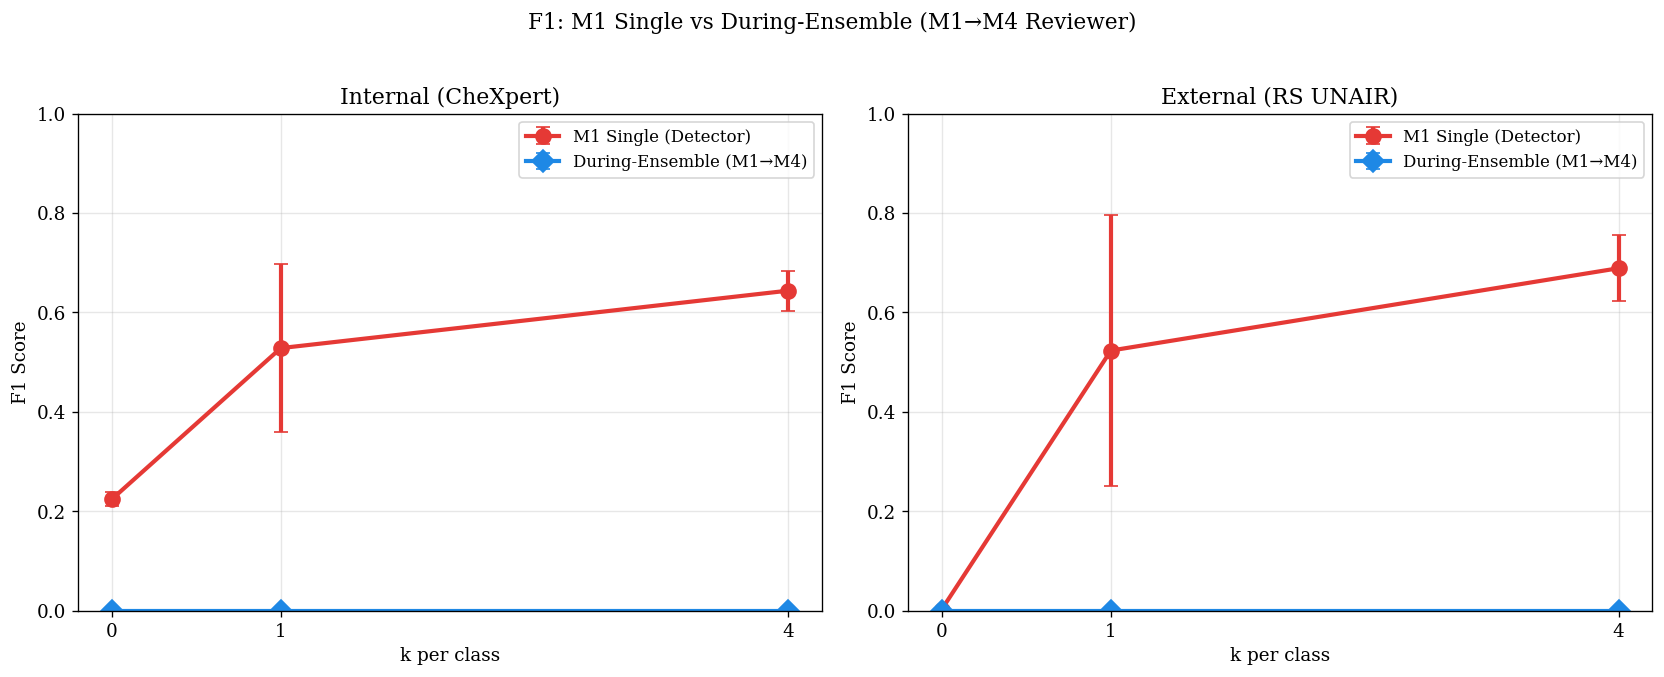

Saved: fig1_f1_during_ensemble


In [16]:
# Fig 1: F1 comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
test_set_names = df_summary['test_set'].unique()

for idx, ts in enumerate(test_set_names):
    ax = axes[idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in ['M1_single', 'During_M1toM4']:
        s = sub[sub['method'] == method].sort_values('k_shot')
        ax.errorbar(
            s['k_shot'], s['f1_mean'], yerr=s['f1_std'],
            label=METHOD_LABELS.get(method, method),
            marker=METHOD_MARKERS.get(method, 'o'),
            color=METHOD_COLORS.get(method),
            capsize=4, linewidth=2.5, markersize=9,
        )
    
    short_ts = 'Internal (CheXpert)' if 'Internal' in ts else 'External (RS UNAIR)'
    ax.set_xlabel('k per class')
    ax.set_ylabel('F1 Score')
    ax.set_title(short_ts)
    ax.set_xticks(K_SHOTS)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 1.0)

plt.suptitle('F1: M1 Single vs During-Ensemble (M1→M4 Reviewer)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig1_f1_during_ensemble.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig1_f1_during_ensemble.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig1_f1_during_ensemble')

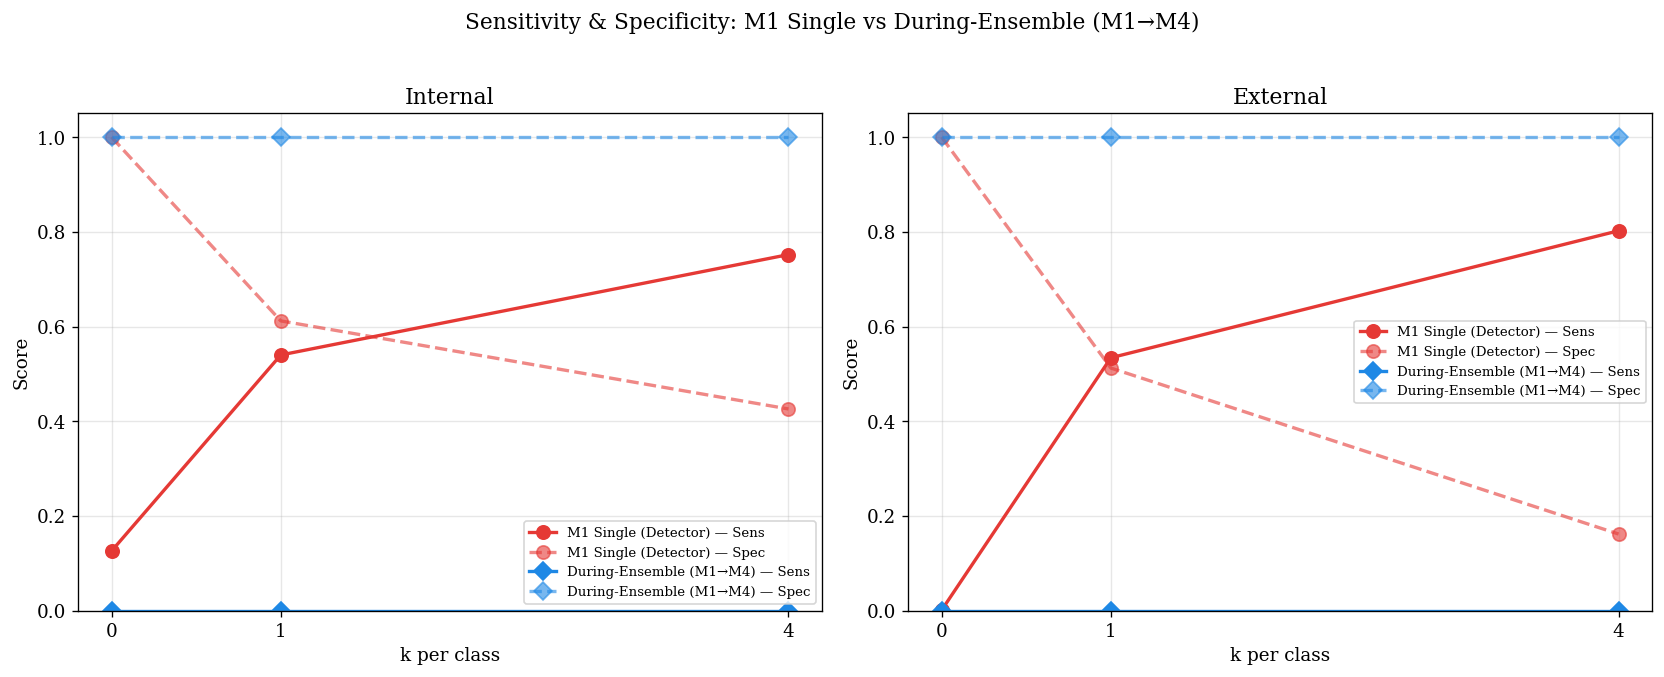

Saved: fig2_sens_spec_during


In [17]:
# Fig 2: Sensitivity & Specificity comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_set_names):
    ax = axes[idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in ['M1_single', 'During_M1toM4']:
        s = sub[sub['method'] == method].sort_values('k_shot')
        color = METHOD_COLORS.get(method)
        label = METHOD_LABELS.get(method, method)
        marker = METHOD_MARKERS.get(method, 'o')
        
        ax.plot(s['k_shot'], s['sensitivity_mean'], '-', marker=marker,
                color=color, linewidth=2, markersize=8, label=f'{label} — Sens')
        ax.plot(s['k_shot'], s['specificity_mean'], '--', marker=marker,
                color=color, linewidth=2, markersize=8, alpha=0.6, label=f'{label} — Spec')
    
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    ax.set_xlabel('k per class')
    ax.set_ylabel('Score')
    ax.set_title(short_ts)
    ax.set_xticks(K_SHOTS)
    ax.legend(fontsize=8)
    ax.set_ylim(0, 1.05)

plt.suptitle('Sensitivity & Specificity: M1 Single vs During-Ensemble (M1→M4)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig2_sens_spec_during.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig2_sens_spec_during.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig2_sens_spec_during')

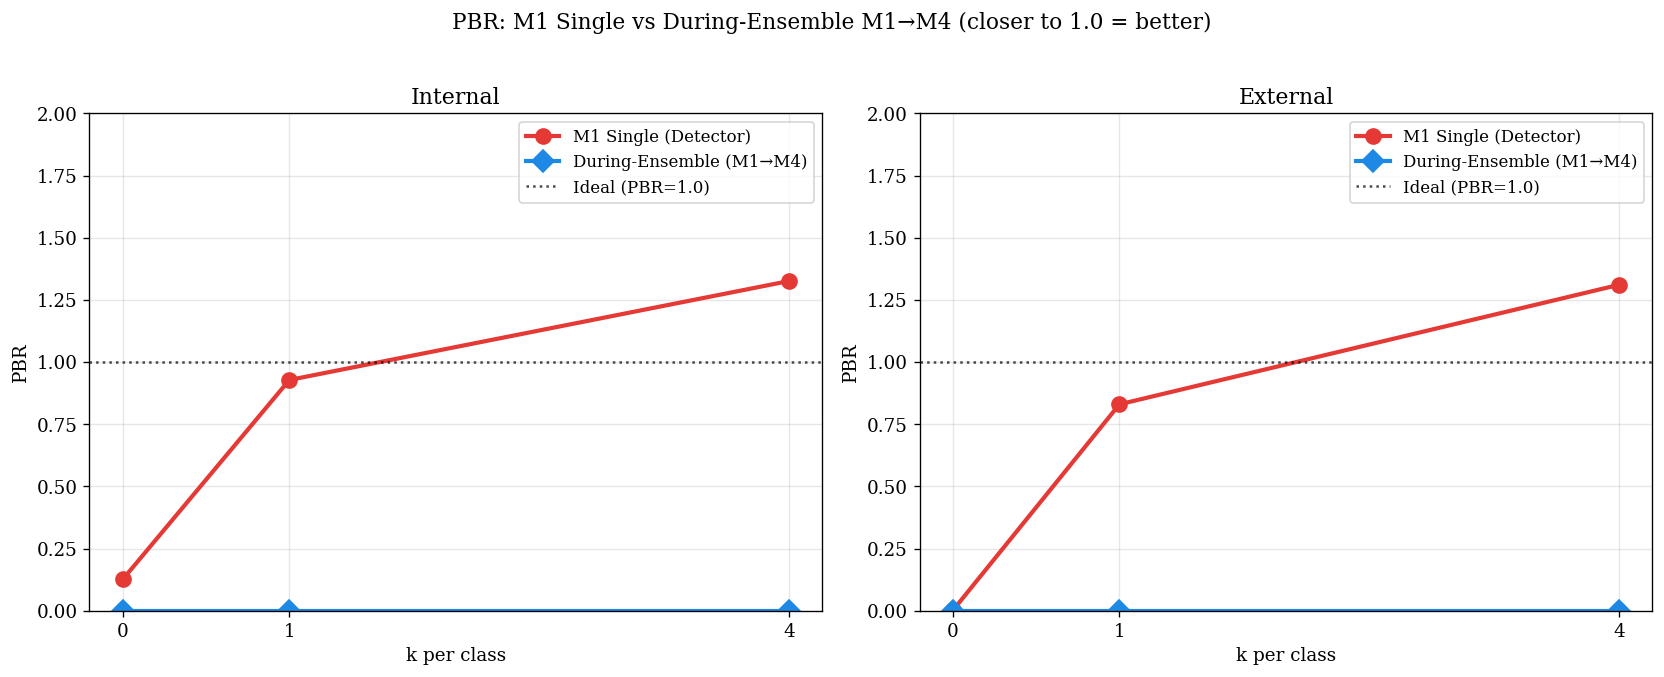

Saved: fig3_pbr_during


In [18]:
# Fig 3: PBR comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, ts in enumerate(test_set_names):
    ax = axes[idx]
    sub = df_summary[df_summary['test_set'] == ts]
    
    for method in ['M1_single', 'During_M1toM4']:
        s = sub[sub['method'] == method].sort_values('k_shot')
        ax.plot(
            s['k_shot'], s['pbr_mean'],
            marker=METHOD_MARKERS.get(method, 'o'),
            color=METHOD_COLORS.get(method),
            label=METHOD_LABELS.get(method, method),
            linewidth=2.5, markersize=9,
        )
    
    ax.axhline(y=1.0, color='black', linewidth=1.5, linestyle=':', alpha=0.7, label='Ideal (PBR=1.0)')
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    ax.set_xlabel('k per class')
    ax.set_ylabel('PBR')
    ax.set_title(short_ts)
    ax.set_xticks(K_SHOTS)
    ax.legend(fontsize=10)
    ax.set_ylim(0, 2.0)

plt.suptitle('PBR: M1 Single vs During-Ensemble M1→M4 (closer to 1.0 = better)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig3_pbr_during.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig3_pbr_during.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig3_pbr_during')

Best k for During-Ensemble M1→M4 (by F1 internal): k=0


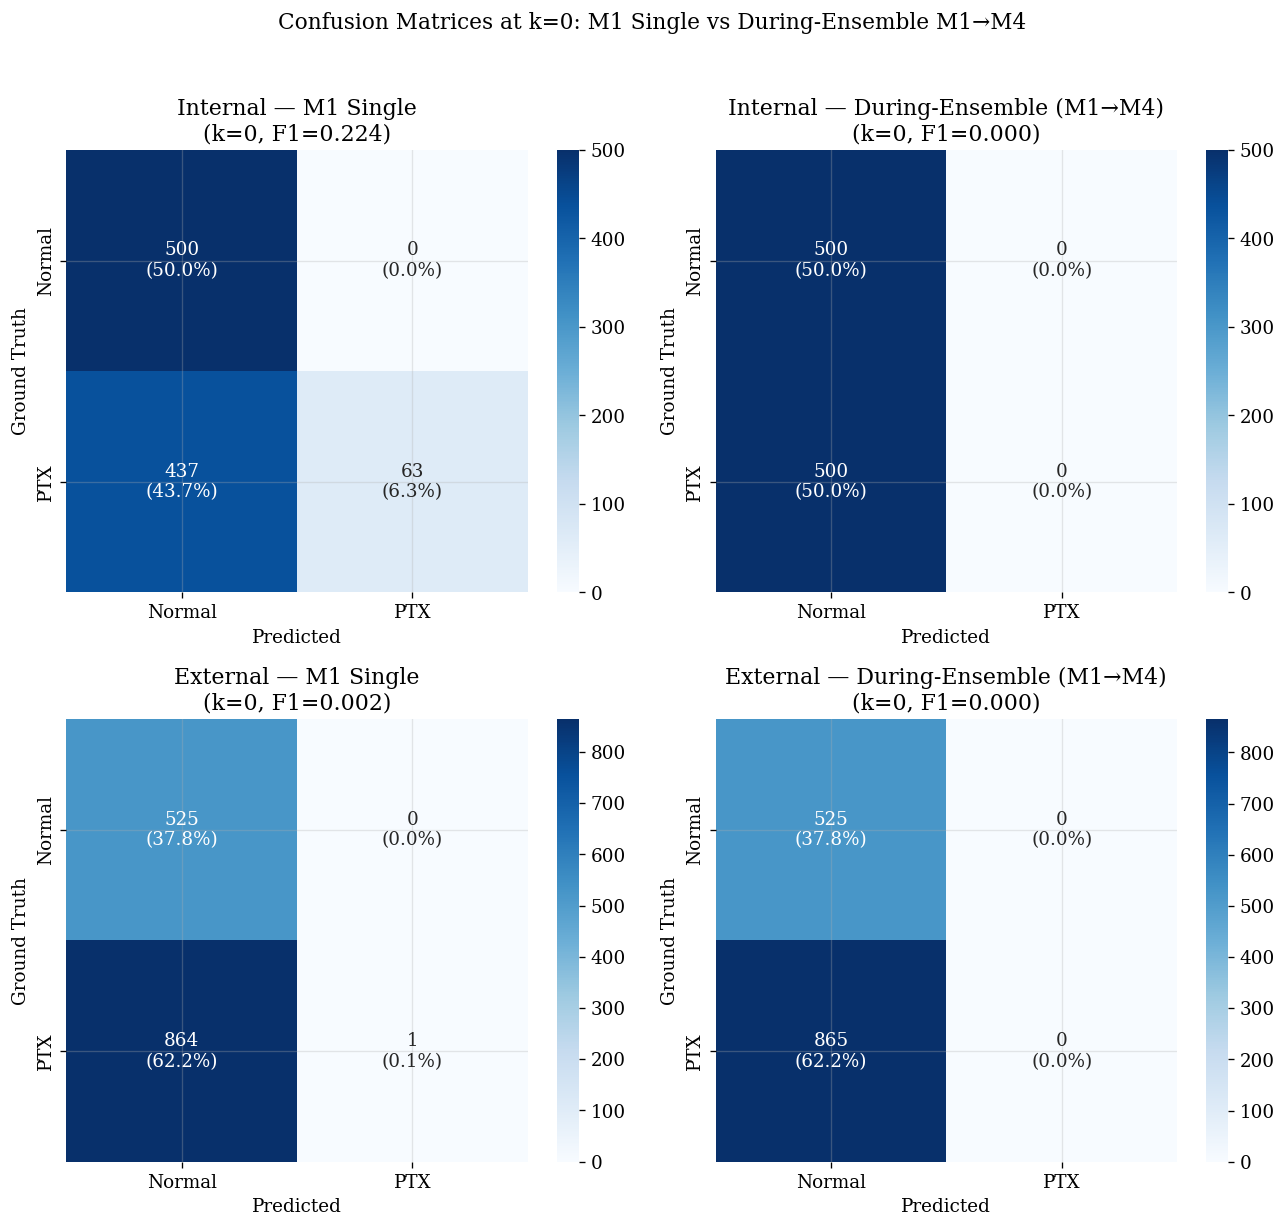

Saved: fig4_confusion_during


In [19]:
# Fig 4: Confusion matrices side-by-side (M1 single vs During-ensemble)
from sklearn.metrics import confusion_matrix as cm_fn, f1_score

# Use best k (by F1) for the comparison
ts_int = [ts for ts in test_set_names if 'Internal' in ts][0]
int_summary = df_summary[(df_summary['test_set'] == ts_int) & (df_summary['method'] == 'During_M1toM4')]
best_k = int(int_summary.loc[int_summary['f1_mean'].idxmax(), 'k_shot'])
print(f"Best k for During-Ensemble M1→M4 (by F1 internal): k={best_k}")

fig, axes = plt.subplots(2, 2, figsize=(11, 10))

configs = [
    ('M1 Single', 'm1_predicted'),
    ('During-Ensemble (M1→M4)', 'm4_predicted'),
]

for ts_idx, ts_name in enumerate(test_set_names):
    sub = df_during[(df_during['k_shot'] == best_k) & (df_during['test_set'] == ts_name)]
    gt = sub['ground_truth'].values
    short_ts = 'Internal' if 'Internal' in ts_name else 'External'
    
    for col_idx, (title, pred_col) in enumerate(configs):
        ax = axes[ts_idx, col_idx]
        preds = sub[pred_col].values
        # Filter valid
        valid = preds != -1
        cm = cm_fn(gt[valid], preds[valid], labels=[0, 1])
        cm_pct = cm.astype(float) / cm.sum() * 100
        annot = np.array([
            [f'{cm[i,j]}\n({cm_pct[i,j]:.1f}%)' for j in range(2)]
            for i in range(2)
        ])
        sns.heatmap(
            cm, annot=annot, fmt='', cmap='Blues',
            xticklabels=['Normal', 'PTX'],
            yticklabels=['Normal', 'PTX'],
            ax=ax, annot_kws={'fontsize': 11},
        )
        f1 = f1_score(gt[valid], preds[valid], zero_division=0)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Ground Truth')
        ax.set_title(f'{short_ts} — {title}\n(k={best_k}, F1={f1:.3f})')

plt.suptitle(f'Confusion Matrices at k={best_k}: M1 Single vs During-Ensemble M1→M4', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig4_confusion_during.png', bbox_inches='tight')
plt.savefig(FIGURES_DIR / 'fig4_confusion_during.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig4_confusion_during')

## 12 — Statistical Tests

In [21]:
from scipy.stats import wilcoxon

print('=' * 80)
print('STATISTICAL TESTS: During-Ensemble M1→M4 vs M1 Single (Wilcoxon, per seed)')
print('=' * 80)

for ts in df_metrics['test_set'].unique():
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    print(f'\n--- {short_ts} ---')
    ts_data = df_metrics[df_metrics['test_set'] == ts]
    
    for k in sorted(ts_data['k_shot'].unique()):
        m1_f1 = ts_data[(ts_data['method'] == 'M1_single') & (ts_data['k_shot'] == k)].sort_values('seed')['f1'].values
        ens_f1 = ts_data[(ts_data['method'] == 'During_M1toM4') & (ts_data['k_shot'] == k)].sort_values('seed')['f1'].values
        
        if len(m1_f1) >= 5 and len(ens_f1) >= 5:
            delta = ens_f1 - m1_f1
            mean_delta = delta.mean()
            
            if len(set(delta)) > 1:
                stat, p = wilcoxon(ens_f1, m1_f1)
            else:
                p = 1.0
            
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            print(f'  k={int(k)}: ΔF1={mean_delta:+.4f}  p={p:.4f} {sig}  '
                  f'(M1={m1_f1.mean():.4f}, During={ens_f1.mean():.4f})')

STATISTICAL TESTS: During-Ensemble M1→M4 vs M1 Single (Wilcoxon, per seed)

--- Internal ---
  k=0: ΔF1=-0.2237  p=0.0625 ns  (M1=0.2237, During=0.0000)
  k=1: ΔF1=-0.5282  p=0.0625 ns  (M1=0.5282, During=0.0000)
  k=4: ΔF1=-0.6438  p=0.0625 ns  (M1=0.6438, During=0.0000)

--- External ---
  k=0: ΔF1=-0.0023  p=1.0000 ns  (M1=0.0023, During=0.0000)
  k=1: ΔF1=-0.5233  p=0.0625 ns  (M1=0.5233, During=0.0000)
  k=4: ΔF1=-0.6889  p=0.0625 ns  (M1=0.6889, During=0.0000)


## 13 — Qualitative Examples: M1 vs M4 Reviewer

In [22]:
# Show cases where M1 and M4-reviewer disagree
df_during['m1_pred'] = df_during['m1_predicted']
df_during['m4_pred'] = df_during['m4_predicted']
df_during['agree'] = df_during['m1_pred'] == df_during['m4_pred']

# Focus on k=best_k, seed=0, internal
focus = df_during[
    (df_during['k_shot'] == best_k) &
    (df_during['seed'] == 0) &
    (df_during['test_set'].str.contains('Internal'))
]

disagree = focus[~focus['agree']]
print(f"Disagreements at k={best_k}, seed=0, Internal: {len(disagree)} / {len(focus)}")
print(f"Agreement rate: {focus['agree'].mean():.3f}")

# Show a few disagreement examples
print(f"\n{'='*80}")
print("DISAGREEMENT EXAMPLES (M1 ≠ M4-reviewer):")
print(f"{'='*80}")

for _, row in disagree.head(5).iterrows():
    gt = 'PTX' if row['ground_truth'] == 1 else 'Normal'
    m1 = 'PTX' if row['m1_pred'] == 1 else 'Normal'
    m4r = 'PTX' if row['m4_pred'] == 1 else 'Normal'
    correct = 'M4-reviewer' if row['m4_pred'] == row['ground_truth'] else 'M1'
    
    print(f"\n  [{row['image_id']}]  GT={gt}  M1={m1}  M4-reviewer={m4r}  → {correct} correct")
    
    # Show M4 reviewer output snippet
    m4_text = row['m4_generated_text']
    # Try to find answer tag
    ans = re.search(r'<answer>(.*?)</answer>', m4_text, re.DOTALL | re.IGNORECASE)
    if ans:
        print(f"    M4 answer: {ans.group(1).strip()[:150]}")
    else:
        # Show last 200 chars which likely contains the conclusion
        print(f"    M4 output (tail): ...{m4_text[-200:]}")

Disagreements at k=0, seed=0, Internal: 14 / 200
Agreement rate: 0.930

DISAGREEMENT EXAMPLES (M1 ≠ M4-reviewer):

  [patient01124_study4_view1_frontal]  GT=PTX  M1=PTX  M4-reviewer=Normal  → M1 correct
    M4 output (tail): ...NO PNEUMOTHORAX DETECTED


  [patient23439_study5_view1_frontal]  GT=PTX  M1=PTX  M4-reviewer=Normal  → M1 correct
    M4 output (tail): ...NO PNEUMOTHORAX DETECTED


  [patient48689_study1_view1_frontal]  GT=PTX  M1=PTX  M4-reviewer=Normal  → M1 correct
    M4 output (tail): ...NO PNEUMOTHORAX DETECTED


  [patient35012_study2_view1_frontal]  GT=PTX  M1=PTX  M4-reviewer=Normal  → M1 correct
    M4 output (tail): ...NO PNEUMOTHORAX DETECTED


  [patient00764_study2_view1_frontal]  GT=PTX  M1=PTX  M4-reviewer=Normal  → M1 correct
    M4 output (tail): ...es a small pneumothorax at the right lung apex. The presence of a chest tube is also noted. The report also mentions atelectasis in the right upper lobe and left lower lobe.

NO PNEUMOTHORAX DETECTED



## 14 — Key Findings

In [23]:
print('=' * 80)
print('KEY FINDINGS — During-Inference Ensemble (M1→M4 Reviewer)')
print('=' * 80)

for ts in df_summary['test_set'].unique():
    short_ts = 'Internal' if 'Internal' in ts else 'External'
    sub = df_summary[df_summary['test_set'] == ts]
    
    print(f'\n--- {short_ts} ---')
    for k in sorted(sub['k_shot'].unique()):
        k_sub = sub[sub['k_shot'] == k]
        m1 = k_sub[k_sub['method'] == 'M1_single'].iloc[0]
        dur = k_sub[k_sub['method'] == 'During_M1toM4'].iloc[0]
        
        f1_delta = dur['f1_mean'] - m1['f1_mean']
        spec_delta = dur['specificity_mean'] - m1['specificity_mean']
        sens_delta = dur['sensitivity_mean'] - m1['sensitivity_mean']
        
        print(f"  k={int(k)}:")
        print(f"    M1 single:       F1={m1['f1_mean']:.3f}  Sens={m1['sensitivity_mean']:.3f}  Spec={m1['specificity_mean']:.3f}  PBR={m1['pbr_mean']:.3f}")
        print(f"    During-Ensemble: F1={dur['f1_mean']:.3f}  Sens={dur['sensitivity_mean']:.3f}  Spec={dur['specificity_mean']:.3f}  PBR={dur['pbr_mean']:.3f}")
        print(f"    Delta:           ΔF1={f1_delta:+.3f}  ΔSens={sens_delta:+.3f}  ΔSpec={spec_delta:+.3f}")

print('\n' + '=' * 80)
print('HARAPAN:')
print('  - F1 during-ensemble > M1 single')
print('  - Specificity meningkat (M4 mem-filter false positive M1)')
print('  - Sensitivity sedikit turun tapi masih reasonable')
print('  - PBR lebih mendekati 1.0')
print('=' * 80)

KEY FINDINGS — During-Inference Ensemble (M1→M4 Reviewer)

--- Internal ---
  k=0:
    M1 single:       F1=0.224  Sens=0.126  Spec=1.000  PBR=0.126
    During-Ensemble: F1=0.000  Sens=0.000  Spec=1.000  PBR=0.000
    Delta:           ΔF1=-0.224  ΔSens=-0.126  ΔSpec=+0.000
  k=1:
    M1 single:       F1=0.528  Sens=0.540  Spec=0.612  PBR=0.928
    During-Ensemble: F1=0.000  Sens=0.000  Spec=1.000  PBR=0.000
    Delta:           ΔF1=-0.528  ΔSens=-0.540  ΔSpec=+0.388
  k=4:
    M1 single:       F1=0.644  Sens=0.752  Spec=0.426  PBR=1.326
    During-Ensemble: F1=0.000  Sens=0.000  Spec=1.000  PBR=0.000
    Delta:           ΔF1=-0.644  ΔSens=-0.752  ΔSpec=+0.574

--- External ---
  k=0:
    M1 single:       F1=0.002  Sens=0.001  Spec=1.000  PBR=0.001
    During-Ensemble: F1=0.000  Sens=0.000  Spec=1.000  PBR=0.000
    Delta:           ΔF1=-0.002  ΔSens=-0.001  ΔSpec=+0.000
  k=1:
    M1 single:       F1=0.523  Sens=0.534  Spec=0.512  PBR=0.830
    During-Ensemble: F1=0.000  Sens=0.000  Spe

## 15 — Export

In [24]:
print('EXPORTED FILES:')
print(f'\nResults:')
for f in sorted(OUTPUT_DIR.glob('*')):
    print(f'  {f.name}')
print(f'\nFigures:')
for f in sorted(FIGURES_DIR.glob('fig*')):
    print(f'  {f.name}')

EXPORTED FILES:

Results:
  all_results_during_ensemble_m1_m4.jsonl
  checkpoint_during_ensemble_m1_m4.jsonl
  during_ensemble_per_seed.csv
  during_ensemble_summary.csv

Figures:
  fig1_f1_during_ensemble.pdf
  fig1_f1_during_ensemble.png
  fig2_sens_spec_during.pdf
  fig2_sens_spec_during.png
  fig3_pbr_during.pdf
  fig3_pbr_during.png
  fig4_confusion_during.pdf
  fig4_confusion_during.png
